# Exploratory Data Analysis (Coastal Waste Detection)

## 1. Library imports

In [7]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import yaml

sns.set_theme(style="whitegrid")

## 2. Dataset configuration

In [8]:
# Define the dataset path
DATA_DIR = Path(
    r"C:\Users\lenam\Documents\GitHub\plastic-waste-detection\data\raw\ucwd\UCWD.yolo"
).resolve()

# Check that the dataset exists
print("Dataset path:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())

# Load dataset configuration
with open(DATA_DIR / "data.yaml", "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

config

Dataset path: C:\Users\lenam\Documents\GitHub\plastic-waste-detection\data\raw\ucwd\UCWD.yolo
Dataset exists: True


{'train': '../train/images',
 'val': '../valid/images',
 'test': '../test/images',
 'nc': 7,
 'names': ['Glass',
  'Metal',
  'Packet',
  'Plastic bag',
  'Plastic bottle',
  'Plastic container',
  'Plastic fragment'],
 'roboflow': {'workspace': 'hesam-nml6z',
  'project': 'all-scvcw',
  'version': 1,
  'license': 'CC BY 4.0',
  'url': 'https://universe.roboflow.com/hesam-nml6z/all-scvcw/dataset/1'}}

## 3. Dataset structure

In [9]:
# Define dataset splits
splits = ["train", "valid", "test"]

# Supported image extensions
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

# Store dataset statistics
stats = []

for split in splits:

    images_dir = DATA_DIR / split / "images"
    labels_dir = DATA_DIR / split / "labels"

    images = [
        file for file in images_dir.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    labels = list(labels_dir.glob("*.txt"))

    stats.append({
        "split": split,
        "images": len(images),
        "labels": len(labels)
    })

# Convert statistics into a DataFrame
df_stats = pd.DataFrame(stats)

df_stats

,split,images,labels
0,train,3071,3071
1,valid,500,500
2,test,500,500


In [10]:
# Calculate total number of images
total_images = df_stats["images"].sum()

# Calculate split percentages
df_stats["percentage"] = (
    df_stats["images"] / total_images * 100
).round(2)

print("Total number of images:", total_images)

df_stats

Total number of images: 4071


,split,images,labels,percentage
0,train,3071,3071,75.44
1,valid,500,500,12.28
2,test,500,500,12.28


In [12]:
# Select the first non-empty training annotation
label_files = (DATA_DIR / "train" / "labels").glob("*.txt")

sample_label = next(
    file for file in label_files
    if file.stat().st_size > 0
)

# Display annotation content
print("File:", sample_label.name)
print()
print(sample_label.read_text(encoding="utf-8"))

File: batch_01_frame_0_jpg.rf.bc525bc8947e822be47291cd8b9faeff.txt

0 0.7864583333333334 0.4351851851851852 0.022395833333333334 0.11296296296296296


## 4. Class distribution

In [13]:
# Store all object annotations
annotations = []

# Get class names from dataset configuration
class_names = config["names"]

for split in splits:

    labels_dir = DATA_DIR / split / "labels"

    for label_file in labels_dir.glob("*.txt"):

        with open(label_file, "r", encoding="utf-8") as file:

            for line in file:

                if not line.strip():
                    continue

                values = line.split()

                class_id = int(values[0])
                x_center = float(values[1])
                y_center = float(values[2])
                width = float(values[3])
                height = float(values[4])

                annotations.append({
                    "split": split,
                    "filename": label_file.stem,
                    "class_id": class_id,
                    "class_name": class_names[class_id],
                    "x_center": x_center,
                    "y_center": y_center,
                    "width": width,
                    "height": height,
                    "area": width * height
                })

# Create annotation DataFrame
df_annotations = pd.DataFrame(annotations)

df_annotations.head()

,split,filename,class_id,class_name,x_center,y_center,width,height,area
0,train,batch_01_frame_0_jpg.rf.bc525bc8947e822be47291...,0,Glass,0.786458,0.435185,0.022396,0.112963,0.002530
1,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,1,Metal,0.271388,0.635324,0.019544,0.033981,0.000664
2,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,1,Metal,0.285151,0.663875,0.016497,0.035440,0.000585
3,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,0,Glass,0.065497,0.981000,0.024049,0.024236,0.000583
4,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,6,Plastic fragment,0.651021,0.174894,0.014323,0.021759,0.000312


In [14]:
# Count total number of annotated objects
print("Total annotated objects:", len(df_annotations))

# Count objects per class
class_counts = df_annotations["class_name"].value_counts()

class_counts

Total annotated objects: 26258


class_name
Plastic bottle       11514
Metal                 4034
Plastic fragment      3839
Glass                 2449
Packet                2099
Plastic container     1559
Plastic bag            764
Name: count, dtype: int64

In [15]:
# Count objects per class and dataset split
class_distribution = pd.crosstab(
    df_annotations["class_name"],
    df_annotations["split"]
)

class_distribution = class_distribution[
    ["train", "valid", "test"]
]

class_distribution

split,train,valid,test
class_name,,,
Glass,1803,327,319
Metal,3046,492,496
Packet,1527,303,269
Plastic bag,575,73,116
Plastic bottle,8740,1340,1434
Plastic container,1154,184,221
Plastic fragment,2934,441,464


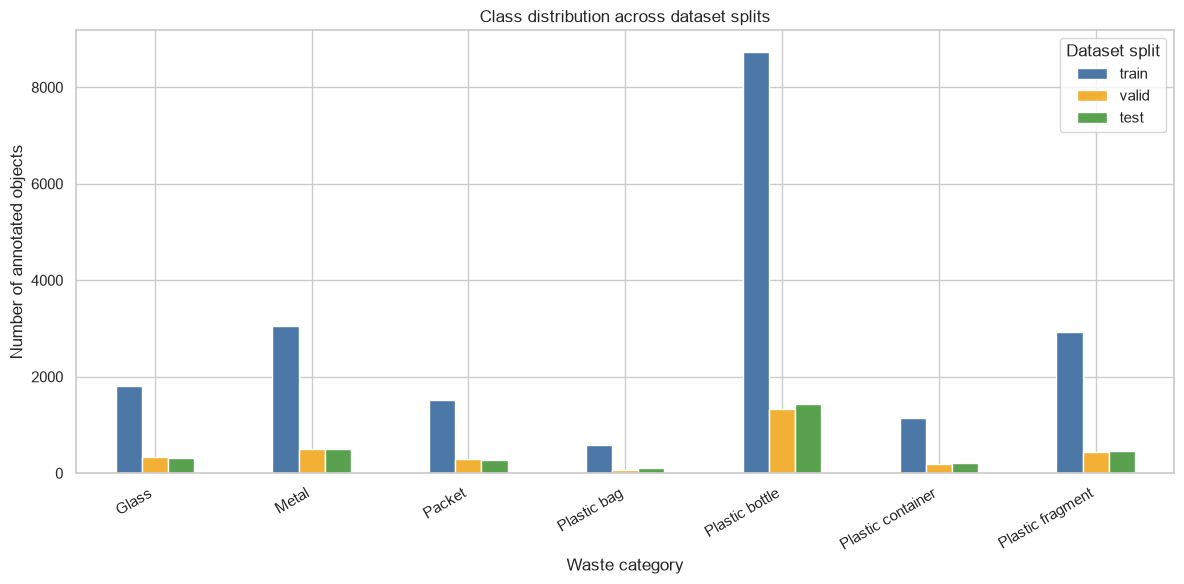

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))

class_distribution.plot(
    kind="bar",
    ax=ax,
    color=["#4C78A8", "#F2B134", "#59A14F"]
)

ax.set_title("Class distribution across dataset splits")
ax.set_xlabel("Waste category")
ax.set_ylabel("Number of annotated objects")
ax.legend(title="Dataset split")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [17]:
# Calculate relative class distribution for each split
class_proportions = (
    class_distribution / class_distribution.sum(axis=0) * 100
)

class_proportions.round(2)

split,train,valid,test
class_name,,,
Glass,9.12,10.35,9.61
Metal,15.40,15.57,14.94
Packet,7.72,9.59,8.10
Plastic bag,2.91,2.31,3.50
Plastic bottle,44.19,42.41,43.21
Plastic container,5.83,5.82,6.66
Plastic fragment,14.83,13.96,13.98


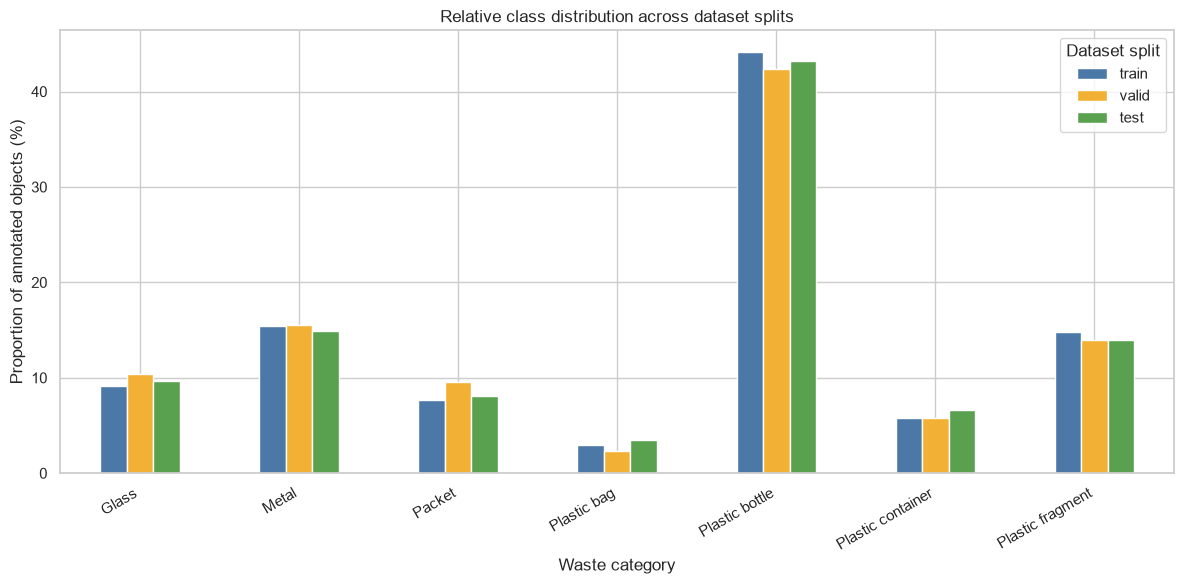

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))

class_proportions.plot(
    kind="bar",
    ax=ax,
    color=["#4C78A8", "#F2B134", "#59A14F"]
)

ax.set_title("Relative class distribution across dataset splits")
ax.set_xlabel("Waste category")
ax.set_ylabel("Proportion of annotated objects (%)")
ax.legend(title="Dataset split")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Interpretation

The dataset contains 26,258 annotated objects distributed across 4,071 images and seven waste categories.

A significant class imbalance is observed. Plastic bottles account for approximately 44% of all annotations, whereas plastic bags represent only 3%.

However, relative class distributions remain broadly consistent across the training, validation and test sets.

This imbalance may affect the detection performance of underrepresented categories. Therefore, class-specific precision, recall and average precision should be monitored during model evaluation.

## 5. Image dimensions

In [19]:
from PIL import Image

# Store image metadata
image_metadata = []

for split in splits:

    images_dir = DATA_DIR / split / "images"

    for image_path in images_dir.iterdir():

        if image_path.suffix.lower() not in image_extensions:
            continue

        with Image.open(image_path) as img:

            width, height = img.size

            image_metadata.append({
                "split": split,
                "filename": image_path.stem,
                "width": width,
                "height": height,
                "aspect_ratio": width / height,
                "megapixels": (width * height) / 1e6
            })

# Create image metadata DataFrame
df_images = pd.DataFrame(image_metadata)

df_images.head()

,split,filename,width,height,aspect_ratio,megapixels
0,train,batch_01_frame_0_jpg.rf.bc525bc8947e822be47291...,3840,2160,1.777778,8.2944
1,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,3840,2160,1.777778,8.2944
2,train,batch_01_frame_11_jpg.rf.50a4d0a2020280a10efd6...,3840,2160,1.777778,8.2944
3,train,batch_01_frame_13_jpg.rf.008d14256c4d381b71efe...,3840,2160,1.777778,8.2944
4,train,batch_01_frame_15_jpg.rf.1a03b1cf484a3627a4484...,3840,2160,1.777778,8.2944


In [20]:
# Count images by resolution
df_images.groupby(
    ["width", "height"]
).size().sort_values(ascending=False)

width  height
3840   2160      1535
1200   800        818
5472   3078       806
3668   1628       328
5472   3648       292
3024   3024       148
4864   3648       100
4000   3000        33
4032   3024         4
960    1280         3
1280   960          2
4056   3040         2
dtype: int64

In [21]:
df_images[
    ["width", "height", "aspect_ratio", "megapixels"]
].describe().round(2)

,width,height,aspect_ratio,megapixels
count,4071.00,4071.00,4071.00,4071.00
mean,3729.55,2207.16,1.70,9.45
std,1472.77,898.73,0.25,6.05
min,960.00,800.00,0.75,0.96
25%,3668.00,1628.00,1.50,5.97
50%,3840.00,2160.00,1.78,8.29
75%,5472.00,3078.00,1.78,16.84
max,5472.00,3648.00,2.25,19.96


## 6. Objects per image

In [23]:
# Count annotated objects per image
objects_per_image = (
    df_annotations
    .groupby(["split", "filename"])
    .size()
    .reset_index(name="object_count")
)

# Include images without annotations
df_images = df_images.merge(
    objects_per_image,
    on=["split", "filename"],
    how="left"
)

df_images["object_count"] = (
    df_images["object_count"]
    .fillna(0)
    .astype(int)
)

df_images["object_count"].describe()

count    4071.000000
mean        6.450012
std         5.972080
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        60.000000
Name: object_count, dtype: float64

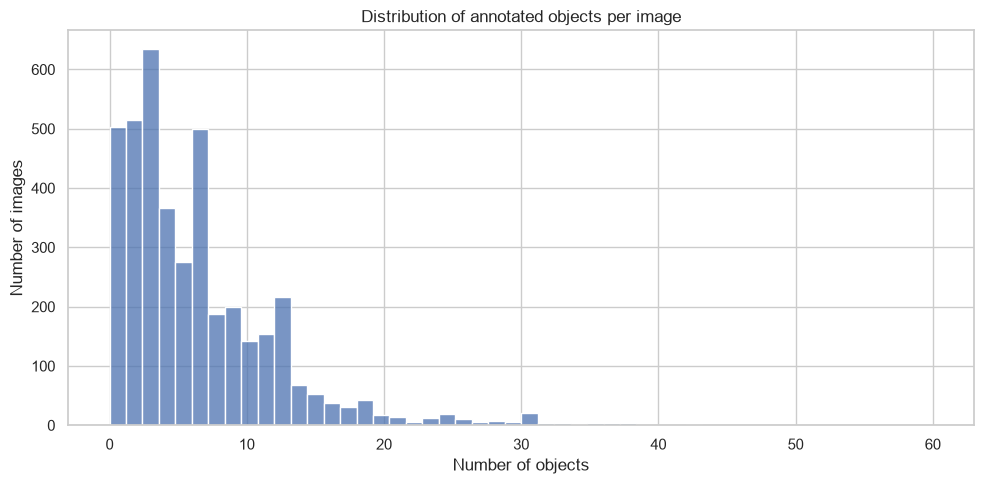

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df_images,
    x="object_count",
    bins=50,
    ax=ax
)

ax.set_title("Distribution of annotated objects per image")
ax.set_xlabel("Number of objects")
ax.set_ylabel("Number of images")

plt.tight_layout()
plt.show()

In [25]:
empty_images = df_images[
    df_images["object_count"] == 0
]

print("Images without annotations:", len(empty_images))

Images without annotations: 91


In [26]:
# Merge annotations with image dimensions
df_objects = df_annotations.merge(
    df_images[
        ["split", "filename", "width", "height"]
    ].rename(columns={
        "width": "image_width",
        "height": "image_height"
    }),
    on=["split", "filename"],
    how="left",
    validate="many_to_one"
)

# Check for unmatched annotations
print(
    "Unmatched annotations:",
    df_objects["image_width"].isna().sum()
)

Unmatched annotations: 0


## 7. Bounding box size distribution

In [27]:
# Original bounding box dimensions in pixels
df_objects["bbox_width_px"] = (
    df_objects["width"] * df_objects["image_width"]
)

df_objects["bbox_height_px"] = (
    df_objects["height"] * df_objects["image_height"]
)

df_objects["bbox_area_px"] = (
    df_objects["bbox_width_px"]
    * df_objects["bbox_height_px"]
)

df_objects.head()

,split,filename,class_id,class_name,x_center,y_center,width,height,area,image_width,image_height,bbox_width_px,bbox_height_px,bbox_area_px
0,train,batch_01_frame_0_jpg.rf.bc525bc8947e822be47291...,0,Glass,0.786458,0.435185,0.022396,0.112963,0.002530,3840,2160,86.00,244.00,20984.0000
1,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,1,Metal,0.271388,0.635324,0.019544,0.033981,0.000664,3840,2160,75.05,73.40,5508.6700
2,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,1,Metal,0.285151,0.663875,0.016497,0.035440,0.000585,3840,2160,63.35,76.55,4849.4425
3,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,0,Glass,0.065497,0.981000,0.024049,0.024236,0.000583,3840,2160,92.35,52.35,4834.5225
4,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,6,Plastic fragment,0.651021,0.174894,0.014323,0.021759,0.000312,3840,2160,55.00,47.00,2585.0000


In [28]:
# Simulate YOLO resizing to 640 pixels
IMG_SIZE = 640

df_objects["resize_scale"] = (
    IMG_SIZE / df_objects[
        ["image_width", "image_height"]
    ].max(axis=1)
)

df_objects["bbox_width_640"] = (
    df_objects["bbox_width_px"]
    * df_objects["resize_scale"]
)

df_objects["bbox_height_640"] = (
    df_objects["bbox_height_px"]
    * df_objects["resize_scale"]
)

df_objects["bbox_area_640"] = (
    df_objects["bbox_width_640"]
    * df_objects["bbox_height_640"]
)

In [29]:
df_objects[
    [
        "bbox_width_px",
        "bbox_height_px",
        "bbox_width_640",
        "bbox_height_640",
        "bbox_area_640"
    ]
].describe().round(2)

,bbox_width_px,bbox_height_px,bbox_width_640,bbox_height_640,bbox_area_640
count,26258.00,26258.00,26258.00,26258.00,26258.00
mean,92.15,91.29,18.25,18.02,720.59
std,85.91,85.26,22.03,21.48,2571.08
min,0.81,0.79,0.09,0.09,0.02
25%,50.16,49.41,7.94,7.84,65.18
50%,68.24,67.16,10.61,10.48,105.75
75%,98.21,98.00,17.21,17.07,246.34
max,2025.00,2009.00,428.57,425.19,129886.62


In [30]:
# Classify objects according to resized bounding box area
df_objects["size_category"] = pd.cut(
    df_objects["bbox_area_640"],
    bins=[0, 32**2, 96**2, np.inf],
    labels=["Small", "Medium", "Large"],
    right=False
)

size_distribution = df_objects[
    "size_category"
].value_counts(sort=False)

size_distribution

size_category
Small     22793
Medium     3103
Large       362
Name: count, dtype: int64

In [31]:
size_by_class = pd.crosstab(
    df_objects["class_name"],
    df_objects["size_category"],
    normalize="index"
) * 100

size_by_class.round(2)

size_category,Small,Medium,Large
class_name,,,
Glass,87.14,12.74,0.12
Metal,92.36,7.14,0.50
Packet,99.57,0.43,0.00
Plastic bag,62.57,34.82,2.62
Plastic bottle,86.57,12.28,1.15
Plastic container,44.71,44.32,10.97
Plastic fragment,96.38,3.20,0.42


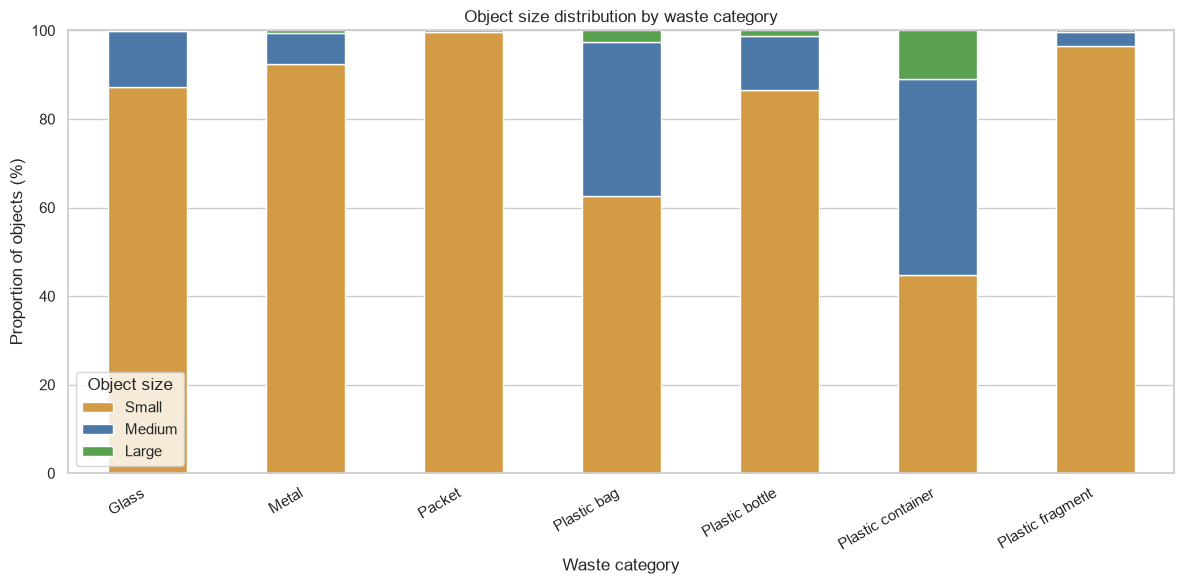

In [32]:
fig, ax = plt.subplots(figsize=(12, 6))

size_by_class.plot(
    kind="bar",
    stacked=True,
    color=["#D49B45", "#4C78A8", "#59A14F"],
    ax=ax
)

ax.set_title("Object size distribution by waste category")
ax.set_xlabel("Waste category")
ax.set_ylabel("Proportion of objects (%)")
ax.legend(title="Object size")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [33]:
# Compare different model input resolutions
input_sizes = [640, 960, 1280]

resolution_stats = []

# Use training annotations for model design decisions
train_objects = df_objects[
    df_objects["split"] == "train"
]

for size in input_sizes:

    scale = size / train_objects[
        ["image_width", "image_height"]
    ].max(axis=1)

    width = train_objects["bbox_width_px"] * scale
    height = train_objects["bbox_height_px"] * scale

    area = width * height
    min_dimension = np.minimum(width, height)

    resolution_stats.append({
        "input_size": size,
        "median_width": width.median(),
        "median_height": height.median(),
        "small_objects_pct": (area < 32**2).mean() * 100,
        "below_8px_pct": (min_dimension < 8).mean() * 100,
        "below_4px_pct": (min_dimension < 4).mean() * 100,
        "below_1px_pct": (min_dimension < 1).mean() * 100
    })

df_resolution = pd.DataFrame(resolution_stats)

df_resolution.round(2)

,input_size,median_width,median_height,small_objects_pct,below_8px_pct,below_4px_pct,below_1px_pct
0,640,10.64,10.48,86.69,42.24,1.73,0.03
1,960,15.96,15.72,80.40,8.85,0.14,0.03
2,1280,21.28,20.95,75.42,1.73,0.05,0.03


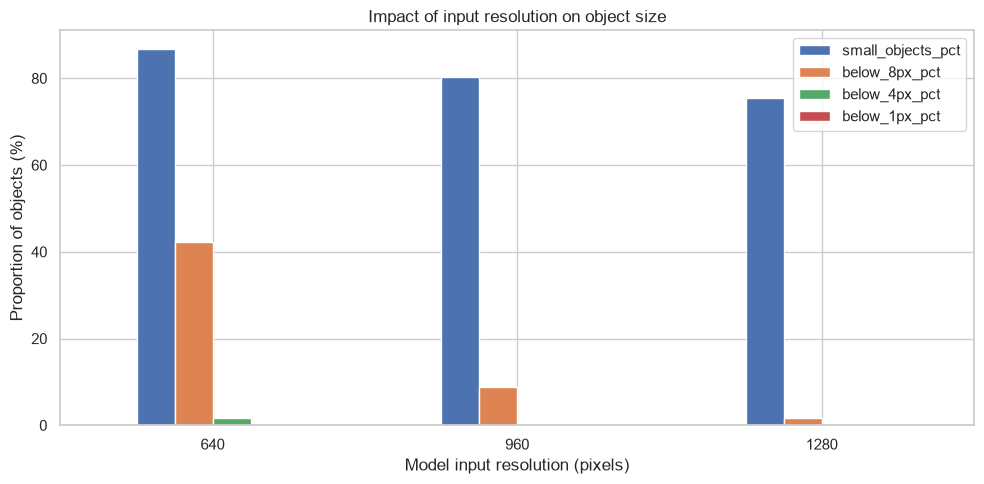

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))

df_resolution.set_index("input_size")[
    [
        "small_objects_pct",
        "below_8px_pct",
        "below_4px_pct",
        "below_1px_pct"
    ]
].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Impact of input resolution on object size")
ax.set_xlabel("Model input resolution (pixels)")
ax.set_ylabel("Proportion of objects (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Interpretation

The dataset presents a significant small-object detection challenge.

After resizing images to 640 pixels, the median bounding box dimensions decrease to approximately 10.6 × 10.5 pixels.

Approximately 87% of annotated objects fall into the small object category, using COCO-inspired area thresholds applied to resized images.

Plastic fragments and packets are particularly affected, with more than 96% of their annotations classified as small objects.

These observations motivate the investigation of alternative preprocessing strategies, including higher input resolutions and image tiling.

### Impact of input resolution

Increasing the input resolution substantially reduces the proportion of extremely small bounding boxes.

At 640 pixels, 42.24% of training objects have a minimum dimension below 8 pixels, compared with 8.85% at 960 pixels and 1.73% at 1280 pixels.

These results suggest that increasing the input resolution could improve small-object detection performance.

An input resolution of 960 pixels may offer a suitable trade-off between spatial detail and computational cost.

This hypothesis will be assessed experimentally during model training and validation.

## 8. Annotation visualization

In [35]:
import matplotlib.patches as patches

def visualize_annotations(image_path, label_path):

    # Load image
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    image_width, image_height = image.size

    fig, ax = plt.subplots(figsize=(16, 10))
    ax.imshow(image)

    # Read annotations
    with open(label_path, "r", encoding="utf-8") as file:

        for line in file:

            if not line.strip():
                continue

            class_id, xc, yc, w, h = map(float, line.split())
            class_id = int(class_id)

            # Convert normalized coordinates to pixels
            x_min = (xc - w / 2) * image_width
            y_min = (yc - h / 2) * image_height

            bbox_width = w * image_width
            bbox_height = h * image_height

            # Create bounding box
            rectangle = patches.Rectangle(
                (x_min, y_min),
                bbox_width,
                bbox_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rectangle)

            # Display class name
            ax.text(
                x_min,
                y_min,
                class_names[class_id],
                color="white",
                fontsize=9,
                bbox=dict(
                    facecolor="red",
                    alpha=0.8,
                    pad=2
                )
            )

    ax.set_title(image_path.name)
    ax.axis("off")

    plt.tight_layout()
    plt.show()

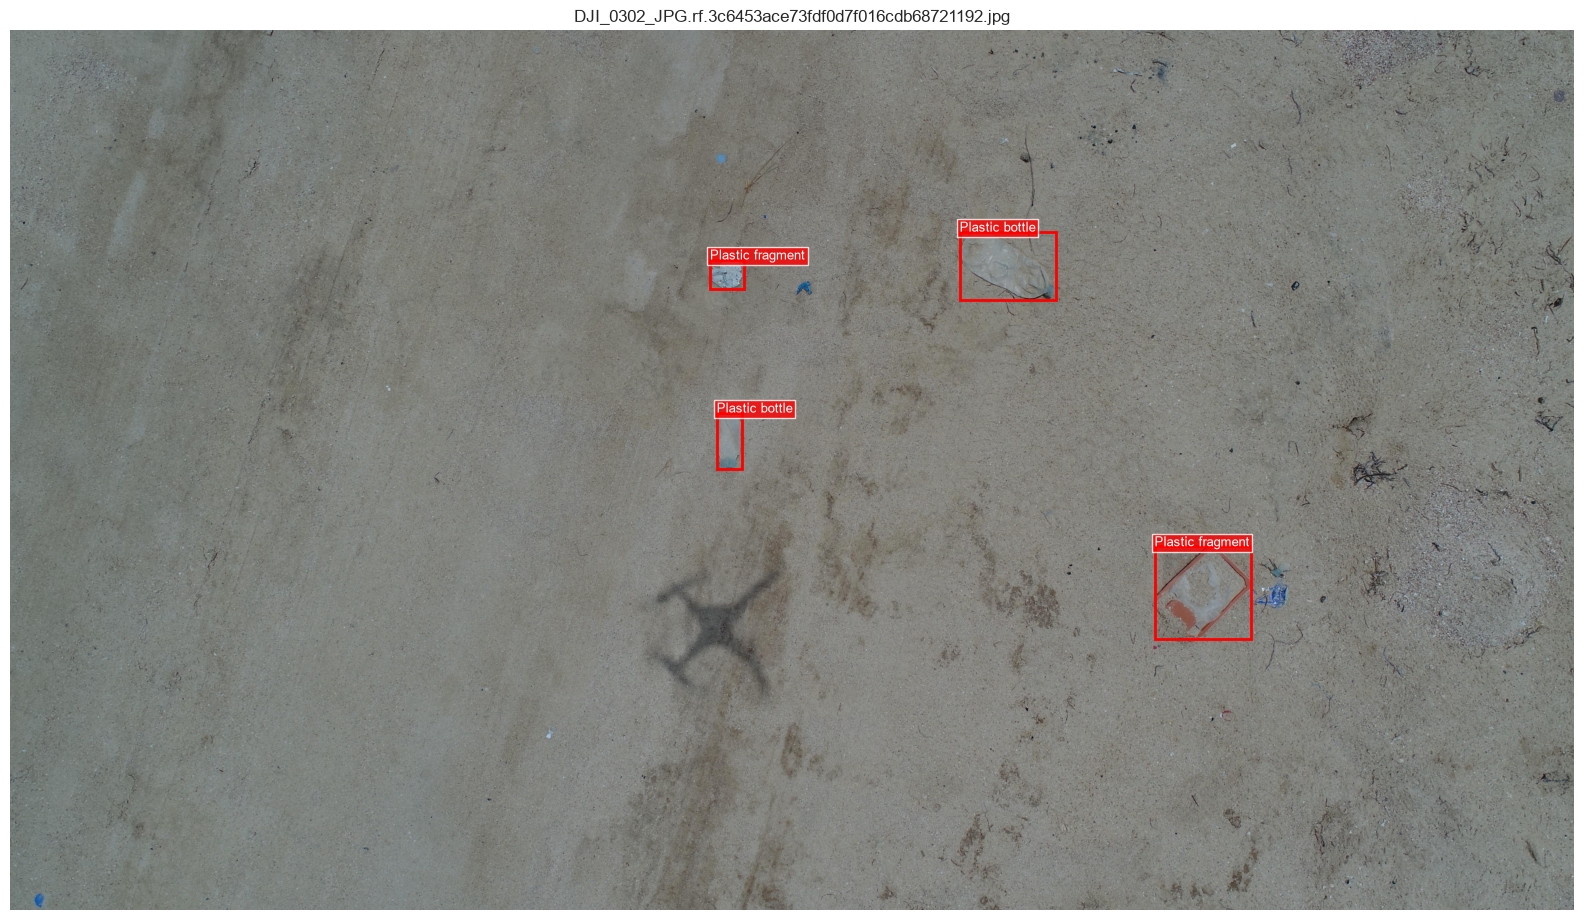

In [40]:
import random

# Select a random training image
train_images = [
    path
    for path in (DATA_DIR / "train" / "images").iterdir()
    if path.suffix.lower() in image_extensions
]

image_path = random.choice(train_images)

# Find the corresponding annotation file
label_path = (
    DATA_DIR / "train" / "labels" /
    f"{image_path.stem}.txt"
)

# Visualize annotations
visualize_annotations(image_path, label_path)

### Visual inspection

Visual inspection reveals substantial variability in object size, image quality and acquisition conditions.

Some objects exhibit low contrast with the sandy background, particularly transparent plastic waste.

Potential missing annotations and ambiguous class assignments were observed and require further
investigation.

The presence of video-derived images also raises
concerns regarding potential data leakage between
training, validation and test sets.

## 9. Data quality assessment

In [41]:
# Check image-label correspondence
for split in splits:

    image_names = set(
        df_images.loc[
            df_images["split"] == split, "filename"
        ]
    )

    label_names = {
        path.stem
        for path in (DATA_DIR / split / "labels").glob("*.txt")
    }

    missing_labels = image_names - label_names
    orphan_labels = label_names - image_names

    print(f"\n{split.upper()}")
    print("Missing labels:", len(missing_labels))
    print("Orphan labels:", len(orphan_labels))


TRAIN
Missing labels: 0
Orphan labels: 0

VALID
Missing labels: 0
Orphan labels: 0

TEST
Missing labels: 0
Orphan labels: 0


In [42]:
# Calculate bounding box boundaries
df_objects["x_min"] = (
    df_objects["x_center"] - df_objects["width"] / 2
)

df_objects["x_max"] = (
    df_objects["x_center"] + df_objects["width"] / 2
)

df_objects["y_min"] = (
    df_objects["y_center"] - df_objects["height"] / 2
)

df_objects["y_max"] = (
    df_objects["y_center"] + df_objects["height"] / 2
)

# Allow a small floating-point tolerance
eps = 1e-6

# Identify invalid bounding boxes
invalid_boxes = df_objects[
    (df_objects["width"] <= 0) |
    (df_objects["height"] <= 0) |
    (df_objects["x_min"] < -eps) |
    (df_objects["y_min"] < -eps) |
    (df_objects["x_max"] > 1 + eps) |
    (df_objects["y_max"] > 1 + eps) |
    (df_objects["class_id"] < 0) |
    (df_objects["class_id"] >= config["nc"])
]

print("Invalid bounding boxes:", len(invalid_boxes))

invalid_boxes.head()

Invalid bounding boxes: 91


,split,filename,class_id,class_name,x_center,y_center,width,height,area,image_width,...,bbox_area_px,resize_scale,bbox_width_640,bbox_height_640,bbox_area_640,size_category,x_min,x_max,y_min,y_max
231,train,batch_04_img_3800_jpg.rf.7e7037606f63f8b11b20c...,6,Plastic fragment,0.013698,0.047546,0.027398,0.048236,0.001322,3840,...,10961.8299,0.166667,17.535000,17.365000,304.495275,Small,-0.000001,0.027397,0.023428,0.071664
430,train,BATCH_d06_img_830_jpg.rf.41e526516754ba43503e8...,6,Plastic fragment,0.595070,0.005426,0.014891,0.010856,0.000162,3840,...,1340.8710,0.166667,9.530000,3.908333,37.246417,Small,0.587625,0.602516,-0.000002,0.010854
730,train,batch_s01_img_2360_jpg.rf.a97545673b5e71111983...,4,Plastic bottle,0.064013,0.031781,0.020785,0.063569,0.001321,3668,...,7890.0776,0.174482,13.302508,18.057143,240.205291,Small,0.053621,0.074406,-0.000003,0.063566
1508,train,CD_1012452_jpg.rf.321908e0c28d26039912aa60985c...,6,Plastic fragment,0.048776,0.067239,0.097553,0.134481,0.013119,3024,...,119967.6500,0.211640,62.433862,86.067725,5373.540494,Medium,0.000000,0.097553,-0.000002,0.134479
2364,train,CD_2947_jpg.rf.c3ebc40a30038475cf541ee5d63d41c3,5,Plastic container,0.699275,0.912738,0.146700,0.174537,0.025605,1200,...,24580.4652,0.533333,93.888000,74.469333,6991.776768,Medium,0.625925,0.772625,0.825469,1.000006


In [43]:
# Identify suspicious subpixel annotations
tiny_boxes = df_objects[
    (df_objects["bbox_width_px"] < 1) |
    (df_objects["bbox_height_px"] < 1)
]

print("Subpixel bounding boxes:", len(tiny_boxes))

print(
    "Percentage:",
    round(len(tiny_boxes) / len(df_objects) * 100, 4),
    "%"
)

tiny_boxes[
    [
        "split",
        "filename",
        "class_name",
        "bbox_width_px",
        "bbox_height_px"
    ]
]

Subpixel bounding boxes: 2
Percentage: 0.0076 %


,split,filename,class_name,bbox_width_px,bbox_height_px
7405,train,DJI_0066_JPG.rf.b3ff7c189673d5640044034305d50e25,Plastic bag,2.09,0.79
10342,train,DJI_0216_JPG.rf.0e2d8b99d86c1341f341deab1692da41,Plastic container,0.81,2.50


In [51]:
# Measure boundary overflow in pixels
df_overflow = invalid_boxes.copy()

df_overflow["max_overflow_px"] = pd.concat(
    [
        -df_overflow["x_min"] * df_overflow["image_width"],
        (df_overflow["x_max"] - 1) * df_overflow["image_width"],
        -df_overflow["y_min"] * df_overflow["image_height"],
        (df_overflow["y_max"] - 1) * df_overflow["image_height"]
    ],
    axis=1
).clip(lower=0).max(axis=1)

# Identify minor boundary errors
minor_errors = df_overflow[
    (df_overflow["max_overflow_px"] > 0) &
    (df_overflow["max_overflow_px"] <= 1) &
    (df_overflow["width"] > 0) &
    (df_overflow["height"] > 0) &
    (df_overflow["class_id"] >= 0) &
    (df_overflow["class_id"] < config["nc"])
]

other_errors = df_overflow.drop(minor_errors.index)

print("Minor boundary errors:", len(minor_errors))
print("Other invalid annotations:", len(other_errors))

display(df_overflow["max_overflow_px"].describe())

Minor boundary errors: 91
Other invalid annotations: 0


count    9.100000e+01
mean     5.000000e-03
std      1.454261e-13
min      5.000000e-03
25%      5.000000e-03
50%      5.000000e-03
75%      5.000000e-03
max      5.000000e-03
Name: max_overflow_px, dtype: float64

All 91 invalid bounding boxes exhibit a maximum boundary overflow of 0.005 pixels.

These negligible deviations are likely caused by numerical rounding during annotation export.

No other invalid annotations were identified.

Bounding box coordinates will be clipped to image
boundaries during preprocessing, preserving all
affected annotations.

## 9. Data quality assessment

In [44]:
# Extract original image names
df_images["original_name"] = (
    df_images["filename"]
    .str.split(".rf.", regex=False)
    .str[0]
)

# Count the number of splits per original image
split_overlap = (
    df_images.groupby("original_name")["split"]
    .nunique()
)

# Identify images potentially shared across splits
shared_images = split_overlap[split_overlap > 1]

print("Shared original image names:", len(shared_images))

shared_images.head(20)

Shared original image names: 187


original_name
DJI_0001_JPG    2
DJI_0003_JPG    3
DJI_0004_JPG    2
DJI_0007_JPG    2
DJI_0009_JPG    2
DJI_0011_JPG    2
DJI_0012_JPG    3
DJI_0014_JPG    3
DJI_0015_JPG    3
DJI_0017_JPG    2
DJI_0018_JPG    2
DJI_0019_JPG    2
DJI_0020_JPG    2
DJI_0022_JPG    2
DJI_0024_JPG    2
DJI_0025_JPG    2
DJI_0026_JPG    2
DJI_0029_JPG    2
DJI_0030_JPG    2
DJI_0031_JPG    2
Name: split, dtype: int64

In [45]:
# Select video-derived images
df_video = df_images[
    df_images["original_name"].str.contains(
        r"_MP4-\d+",
        case=False,
        regex=True
    )
].copy()

# Extract video identifiers
df_video["video_id"] = (
    df_video["original_name"]
    .str.replace(
        r"_MP4-\d+.*$",
        "",
        case=False,
        regex=True
    )
)

# Count images per video and split
video_distribution = pd.crosstab(
    df_video["video_id"],
    df_video["split"]
)

video_distribution

split,test,train,valid
video_id,,,
VID_20230622_133111_0001,20,120,19
VID_20230623_101846_0015,5,37,6
VID_20230623_102039_0016,6,22,5
VID_20230623_102217_0018,7,45,10
VID_20230623_102404_0020,0,16,3
VID_20230623_103349_0021,8,56,12
VID_20230623_103551_0022,9,58,10
VID_20230630_175708_0023,5,33,4
VID_20230630_175827_0024,6,40,7


In [46]:
# Identify videos shared across splits
video_overlap = video_distribution[
    (video_distribution > 0).sum(axis=1) > 1
]

print("Video-derived images:", len(df_video))
print("Identified videos:", df_video["video_id"].nunique())
print("Videos shared across splits:", len(video_overlap))

video_overlap

Video-derived images: 1151
Identified videos: 23
Videos shared across splits: 23


split,test,train,valid
video_id,,,
VID_20230622_133111_0001,20,120,19
VID_20230623_101846_0015,5,37,6
VID_20230623_102039_0016,6,22,5
VID_20230623_102217_0018,7,45,10
VID_20230623_102404_0020,0,16,3
VID_20230623_103349_0021,8,56,12
VID_20230623_103551_0022,9,58,10
VID_20230630_175708_0023,5,33,4
VID_20230630_175827_0024,6,40,7


In [47]:
import hashlib

def compute_file_hash(image_path):

    hasher = hashlib.sha256()

    with open(image_path, "rb") as file:

        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

In [48]:
from tqdm.auto import tqdm

hash_records = []

for split in splits:

    image_paths = [
        path
        for path in (DATA_DIR / split / "images").iterdir()
        if path.suffix.lower() in image_extensions
    ]

    for image_path in tqdm(image_paths, desc=split):

        hash_records.append({
            "split": split,
            "filename": image_path.stem,
            "sha256": compute_file_hash(image_path)
        })

df_hashes = pd.DataFrame(hash_records)

train:   0%|          | 0/3071 [00:00<?, ?it/s]

valid:   0%|          | 0/500 [00:00<?, ?it/s]

test:   0%|          | 0/500 [00:00<?, ?it/s]

In [49]:
# Identify identical files across splits
hash_overlap = (
    df_hashes.groupby("sha256")["split"]
    .nunique()
)

shared_hashes = hash_overlap[hash_overlap > 1]

exact_duplicates = df_hashes[
    df_hashes["sha256"].isin(shared_hashes.index)
].sort_values("sha256")

print("Shared file hashes:", len(shared_hashes))
print("Images involved:", len(exact_duplicates))

exact_duplicates.head(20)

Shared file hashes: 0
Images involved: 0


,split,filename,sha256


### Exact duplicate detection

SHA-256 hashing was performed on all 4,071 images
to identify identical files across dataset splits.

No identical files were detected across the training, validation and test sets.

However, this method cannot identify visually similar images or recompressed versions of the same image.

The absence of exact duplicates therefore does not
eliminate the risk of temporal data leakage identified in video-derived images.

## 10. Conclusion

The exploratory data analysis of the Unified Coastal Waste Dataset (UCWD) highlighted several important challenges for coastal litter detection.

### Key findings

- The dataset contains 4,071 images and 26,258 annotated objects across seven classes.
- The class distribution is imbalanced, with plastic bottles representing 43.85% of all annotations.
- Image resolutions and acquisition conditions are highly heterogeneous.
- Most objects become very small when images are resized to a standard 640-pixel model input.
- Minor annotation boundary errors were identified, but overall structural data quality is satisfactory.
- All 23 identified video sequences are shared across multiple dataset splits, indicating a substantial risk of temporal data leakage.
- No exact binary duplicates were found across splits.

### Implications for model development

Based on these findings, the following strategies
will be implemented:

1. Correction of minor bounding box boundary errors.
2. Verification of subpixel annotations.
3. Reconstruction of dataset splits using acquisition groups to mitigate data leakage.
4. Training of a baseline YOLO model.
5. Investigation of higher input resolutions and
   image tiling for small object detection.
6. Evaluation of model performance globally and
   individually for each class.

The original dataset will remain unchanged to ensure reproducibility and traceability.